In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv("AB_NYC_2019.csv")

df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [5]:
df = pd.read_csv("AB_NYC_2019.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (48895, 16)

Column Names:
Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')

Data Types:
id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availa

In [6]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["str", "object", "category"]).columns

print("Numerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

print("\nNumber of Numerical Columns:", len(numerical_cols))
print("Number of Categorical Columns:", len(categorical_cols))

Numerical Columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical Columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']

Number of Numerical Columns: 10
Number of Categorical Columns: 6


In [7]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_data = missing_data[missing_data["Missing Values"] > 0]

missing_data.sort_values(by="Missing Values", ascending=False)

,Missing Values,Missing Percentage
reviews_per_month,10052,20.558339
last_review,10052,20.558339
host_name,21,0.042949
name,16,0.032723


In [8]:
df[df["last_review"].isnull()]["number_of_reviews"].value_counts().head()

number_of_reviews
0    10052
Name: count, dtype: int64

In [9]:
df = df.drop(columns=["last_review"])

print(df.shape)

(48895, 15)


In [10]:
df[df["reviews_per_month"].isnull()]["number_of_reviews"].value_counts()

number_of_reviews
0    10052
Name: count, dtype: int64

In [11]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

df["reviews_per_month"].isnull().sum()

np.int64(0)

In [12]:
df = df.drop(columns=["id", "host_id", "name", "host_name"])

print(df.shape)
print(df.columns)

(48895, 11)
Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')


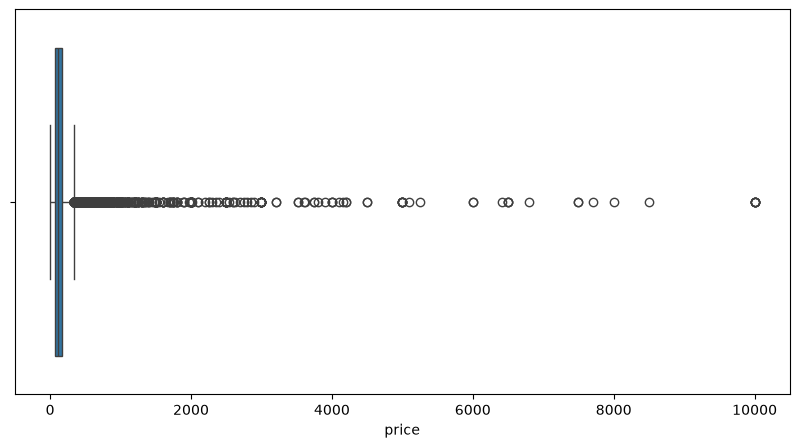

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["price"])
plt.show()

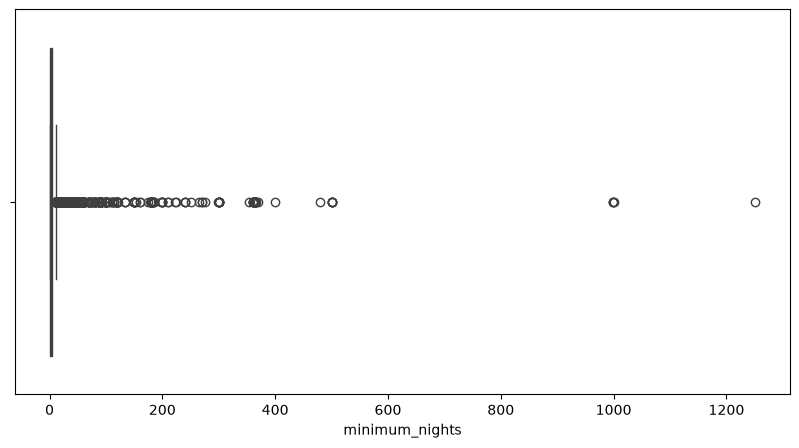

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["minimum_nights"])
plt.show()

In [15]:
price_limit = df["price"].quantile(0.95)
nights_limit = df["minimum_nights"].quantile(0.95)

print("95th percentile of price:", price_limit)
print("95th percentile of minimum nights:", nights_limit)

95th percentile of price: 355.0
95th percentile of minimum nights: 30.0


In [16]:
df = df[
    (df["price"] <= price_limit) &
    (df["minimum_nights"] <= nights_limit)
]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (45759, 11)


In [17]:
print("Unique neighbourhoods:", df["neighbourhood"].nunique())
print("Unique neighbourhood groups:", df["neighbourhood_group"].nunique())

Unique neighbourhoods: 219
Unique neighbourhood groups: 5


In [18]:
df = df.drop(columns=["neighbourhood"])

print(df.shape)
print(df.columns)

(45759, 10)
Index(['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='str')


In [19]:
df = pd.get_dummies(
    df,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)

print(df.shape)
print(df.columns)

(45759, 14)
Index(['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'neighbourhood_group_Brooklyn',
       'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens',
       'neighbourhood_group_Staten Island', 'room_type_Private room',
       'room_type_Shared room'],
      dtype='str')


In [20]:
X = df.drop(columns=["price"])
y = df["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45759, 13)
y shape: (45759,)


In [21]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36607, 13)
X_test: (9152, 13)
y_train: (36607,)
y_test: (9152,)


In [24]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training complete")
print("First 10 predictions:", y_pred[:10])

Model training complete
First 10 predictions: [173.31999192 157.35088508 173.11463763 182.65747453 186.31011596
 165.57173509 128.75527424  59.73992377 191.65680481  99.05073498]


In [25]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.47082773500020925
MAE: 38.540874915538765
MSE: 2834.9593788926663
RMSE: 53.244336589844615


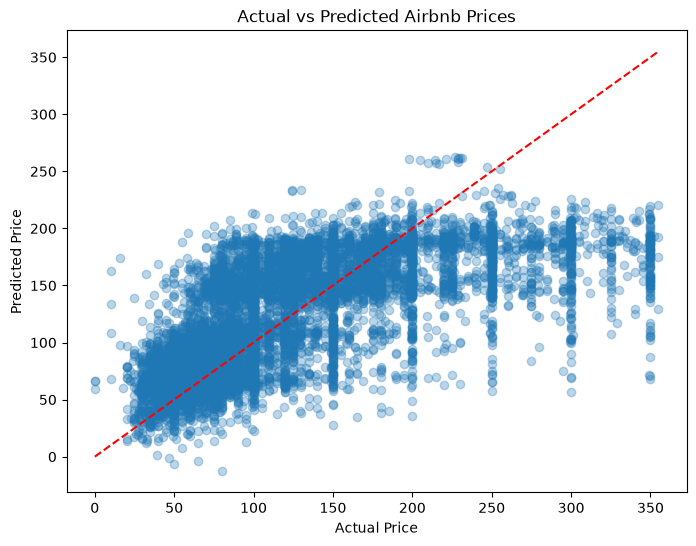

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()

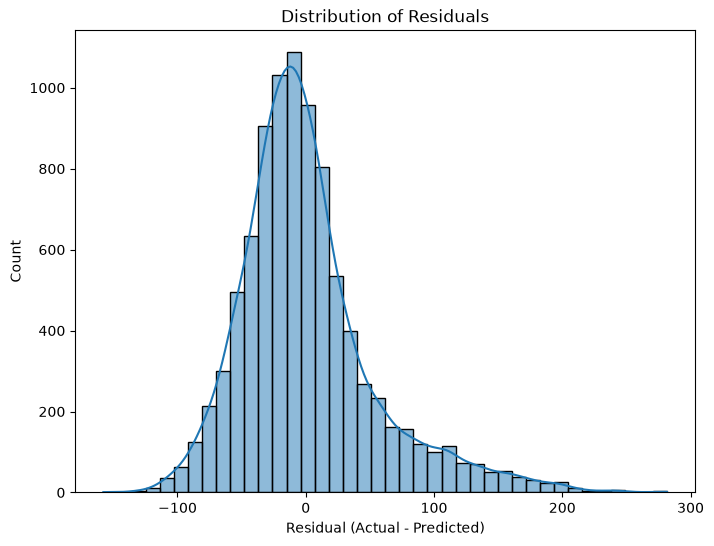

In [27]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
sns.histplot(residuals, bins=40, kde=True)
plt.xlabel("Residual (Actual - Predicted)")
plt.title("Distribution of Residuals")
plt.show()

In [28]:
results = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": y_pred
})

results["Absolute_Error"] = abs(
    results["Actual_Price"] - results["Predicted_Price"]
)

results["Price_Group"] = np.where(
    results["Actual_Price"] <= results["Actual_Price"].median(),
    "Cheap",
    "Expensive"
)

print(results.groupby("Price_Group")["Absolute_Error"].mean())

Price_Group
Cheap        29.027664
Expensive    48.579631
Name: Absolute_Error, dtype: float64
